<a href="https://colab.research.google.com/github/ML-HW-SYS/a4-AaronGoldblatt/blob/main/2-svd_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Low-Rank Approximation

In this section, you will be asked to investigated how the trade-off between
the selected ranks of SVD and its performance in terms of reconstruction
accuracy and speed-up (in clock-time and in FLOPS).

## 1. Set-up

In [1]:
# Mount google drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
# Make sure your token is stored in a txt file at the location below.
# This way there is no risk that you will push it to your repo
# Never share your token with anyone, it is basically your github password!
with open('/content/gdrive/MyDrive/ece5545/token.txt') as f:
    token = f.readline().strip()
# Use another file to store your github username
with open('/content/gdrive/MyDrive/ece5545/git_username.txt') as f:
    handle = f.readline().strip()

In [44]:
# Clone your github repo
YOUR_TOKEN = token
YOUR_HANDLE = handle
BRANCH = "main"

%mkdir /content/gdrive/MyDrive/ece5545
%cd /content/gdrive/MyDrive/ece5545
!git clone https://{YOUR_TOKEN}@github.com/ML-HW-SYS/a4-{YOUR_HANDLE}.git
%cd /content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}
!git checkout {BRANCH}
!git pull

PROJECT_ROOT = f"/content/gdrive/MyDrive/ece5545/a4-{YOUR_HANDLE}"

mkdir: cannot create directory ‘/content/gdrive/MyDrive/ece5545’: File exists
/content/gdrive/MyDrive/ece5545
fatal: destination path 'a4-AaronGoldblatt' already exists and is not an empty directory.
/content/gdrive/MyDrive/ece5545/a4-AaronGoldblatt
Already on 'main'
Your branch is up to date with 'origin/main'.
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4 (delta 2), reused 4 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 445 bytes | 8.00 KiB/s, done.
From https://github.com/ML-HW-SYS/a4-AaronGoldblatt
   11b0d32..49ae099  main       -> origin/main
Updating 11b0d32..49ae099
Fast-forward
 src/matmul.py | 3 +++
 1 file changed, 3 insertions(+)


In [4]:
# This extension reloads all imports before running each cell
%load_ext autoreload
%autoreload 2

Verify the following cell prints your github repository.

In [5]:
!ls {PROJECT_ROOT}


1-numerical_precision.ipynb	 mnist.py
2-svd_rank.ipynb		 README.md
comparison_errors_log_scale.png  src
comparison_errors.png		 svd_combined_error_plot.png
data				 svd_errors_by_rank_and_precision.png
fft_error_log_plot.png		 tests
im2col_error_log_plot.png	 winograd_error_plots.png
logmatmul_error_log_plot.png


In [6]:
# Install required packgaes
!pip install torch numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 59.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

# 2. Rank v.s. Reconstruction Error

In this following cell(s), please plot the number of ranks preserved for A matrix (in the x-axis)
and the reconstruction error of the matrix (in the y-axis, measured by the Frobenius Norm).

NOTE: you can use `svd(A, torch.eye(A.shape(2), rank_A=<rank>, rank_B=None)` to do SVD, drop the rank
to `<rank>`, and return the reconstruction matrix of `A`.

We will provide a series of matrix for you to study. Please make one plot per matrix.
For each plot, comment on the trade-off between the number of ranks selected and the error by answering
the following questions:
1. Is the reconstruction error increasing or decreasing as we add more rank?
2. How fast is the reconstruction error change as we add more rank? Is it changing quickly or slowly? Why?
3. Is there a rank number below/above which the reconstruction error increase significantly?
4. What can you learn about this data?

In [7]:
def reconstruction_error(true, pred):
    """Calculate Frobenius norm error between matrices"""
    return torch.norm(true - pred, p='fro').item()

In [23]:
import torch
import matplotlib.pyplot as plt
from src.matmul import svd

def plot_error_vs_rank(matrix, max_rank=None, task='Matrix'):
    """Plot reconstruction error vs rank for a matrix with both regular and log scales

    Args:
        matrix: The input matrix to analyze
        max_rank: Maximum rank to test (default: min dimension of matrix)
        task: Description of the matrix for the plot title
    """
    # Determine maximum rank if not specified
    if max_rank is None:
        max_rank = min(matrix.shape)

    rank_values = list(range(1, max_rank + 1))

    # Calculate errors for each rank
    errors = []
    print(f"Analyzing {task} with shape {matrix.shape}")

    for rank in rank_values:
        reconstructed_matrix = svd(matrix, torch.eye(matrix.shape[1]), rank_A=rank, rank_B=None)
        error = reconstruction_error(matrix, reconstructed_matrix)
        errors.append(error)
        print(f"  Rank {rank}/{max_rank}: Error = {error:.5e}")

    # Create a figure with two subplots: regular scale and log scale
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Regular scale plot
    ax1.plot(rank_values, errors, 'bo-', markersize=4)
    ax1.set_xlabel('Rank')
    ax1.set_ylabel('Reconstruction Error (Frobenius Norm)')
    ax1.set_title(f'Reconstruction Error vs Rank for {task} (Linear Scale)')
    ax1.grid(True, alpha=0.3)

    # Log scale plot
    ax2.plot(rank_values, errors, 'ro-', markersize=4)
    ax2.set_xlabel('Rank')
    ax2.set_ylabel('Reconstruction Error (Frobenius Norm)')
    ax2.set_title(f'Reconstruction Error vs Rank for {task} (Log Scale)')
    ax2.set_yscale('log')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig(f'svd_rank_{task.replace(" ", "_")}.png')
    plt.show()

    return rank_values, errors

Analyzing Cat Image with shape torch.Size([262144, 3])
  Rank 1/3: Error = 4.35075e+01
  Rank 2/3: Error = 6.29492e+00
  Rank 3/3: Error = 2.59875e-03


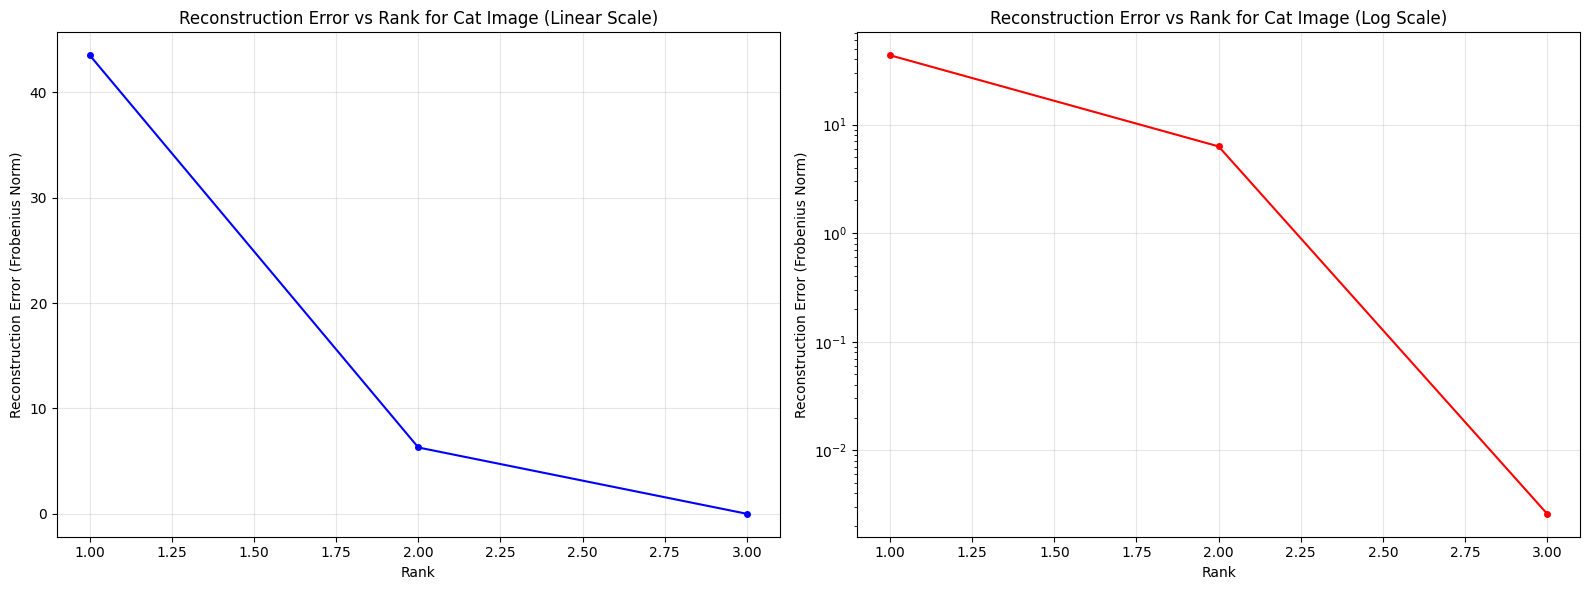

In [24]:
from src.matmul import svd
import torch
import matplotlib.image
# Pixels of a cute cat
A = torch.from_numpy(matplotlib.image.imread("data/cat.png")).view(-1, 3)
max_rank = min(A.shape)
cat_ranks, cat_errors = plot_error_vs_rank(A, max_rank, task='Cat Image')

Analyzing MNIST Batch with shape torch.Size([512, 784])
  Rank 1/512: Error = 5.24571e+02
  Rank 2/512: Error = 5.02444e+02
  Rank 3/512: Error = 4.81446e+02
  Rank 4/512: Error = 4.61383e+02
  Rank 5/512: Error = 4.43575e+02
  Rank 6/512: Error = 4.28516e+02
  Rank 7/512: Error = 4.15957e+02
  Rank 8/512: Error = 4.05060e+02
  Rank 9/512: Error = 3.95309e+02
  Rank 10/512: Error = 3.86197e+02
  Rank 11/512: Error = 3.78384e+02
  Rank 12/512: Error = 3.70530e+02
  Rank 13/512: Error = 3.62941e+02
  Rank 14/512: Error = 3.55968e+02
  Rank 15/512: Error = 3.49464e+02
  Rank 16/512: Error = 3.43086e+02
  Rank 17/512: Error = 3.37070e+02
  Rank 18/512: Error = 3.31443e+02
  Rank 19/512: Error = 3.25912e+02
  Rank 20/512: Error = 3.20483e+02
  Rank 21/512: Error = 3.15430e+02
  Rank 22/512: Error = 3.10392e+02
  Rank 23/512: Error = 3.05365e+02
  Rank 24/512: Error = 3.00666e+02
  Rank 25/512: Error = 2.96048e+02
  Rank 26/512: Error = 2.91551e+02
  Rank 27/512: Error = 2.86999e+02
  Rank 2

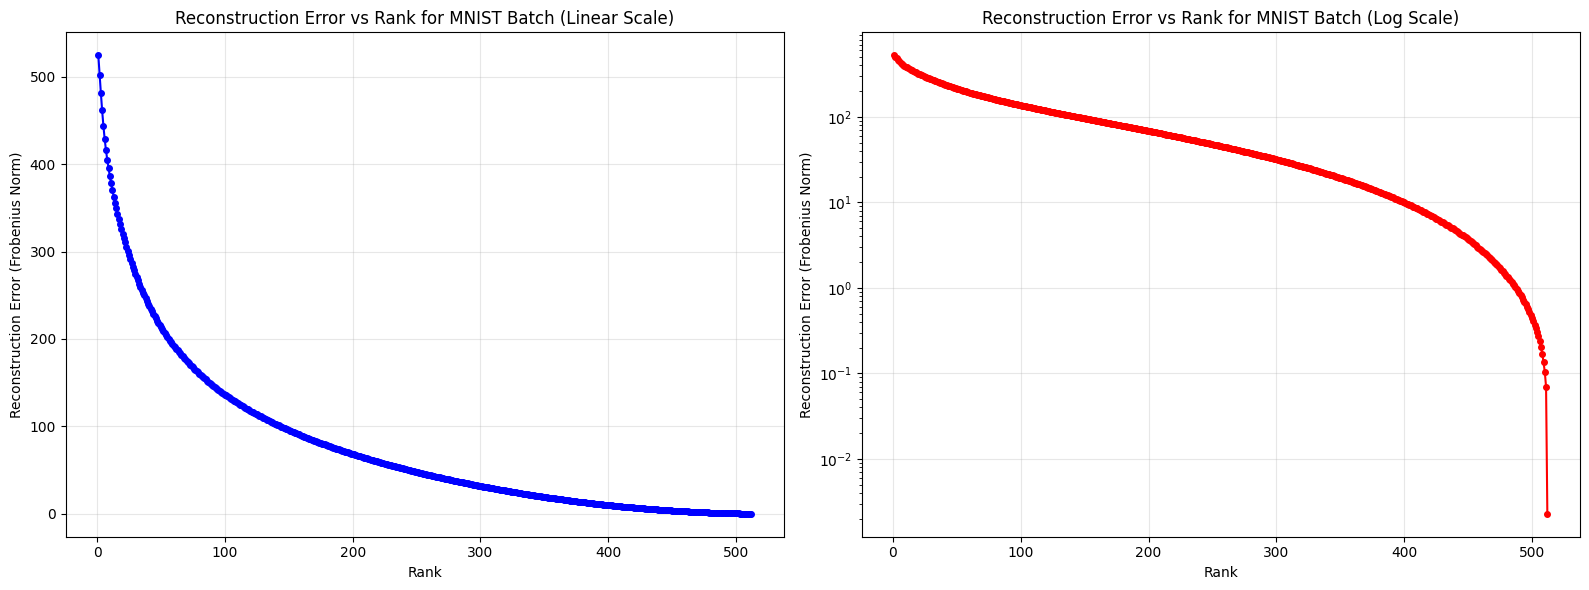

In [25]:
# A batch of MNIST digit
import torch
A = torch.load("data/mnist_act.pt")['act.0']
max_rank = min(A.shape)
mnist_batch_ranks, mnist_batch_errors = plot_error_vs_rank(A, max_rank, task='MNIST Batch')

Analyzing Random Matrix with shape torch.Size([512, 512])
  Rank 1/512: Error = 5.10064e+02
  Rank 2/512: Error = 5.08131e+02
  Rank 3/512: Error = 5.06210e+02
  Rank 4/512: Error = 5.04299e+02
  Rank 5/512: Error = 5.02424e+02
  Rank 6/512: Error = 5.00564e+02
  Rank 7/512: Error = 4.98713e+02
  Rank 8/512: Error = 4.96858e+02
  Rank 9/512: Error = 4.95036e+02
  Rank 10/512: Error = 4.93230e+02
  Rank 11/512: Error = 4.91424e+02
  Rank 12/512: Error = 4.89620e+02
  Rank 13/512: Error = 4.87834e+02
  Rank 14/512: Error = 4.86047e+02
  Rank 15/512: Error = 4.84267e+02
  Rank 16/512: Error = 4.82501e+02
  Rank 17/512: Error = 4.80735e+02
  Rank 18/512: Error = 4.78993e+02
  Rank 19/512: Error = 4.77256e+02
  Rank 20/512: Error = 4.75523e+02
  Rank 21/512: Error = 4.73799e+02
  Rank 22/512: Error = 4.72087e+02
  Rank 23/512: Error = 4.70378e+02
  Rank 24/512: Error = 4.68672e+02
  Rank 25/512: Error = 4.66966e+02
  Rank 26/512: Error = 4.65268e+02
  Rank 27/512: Error = 4.63590e+02
  Rank

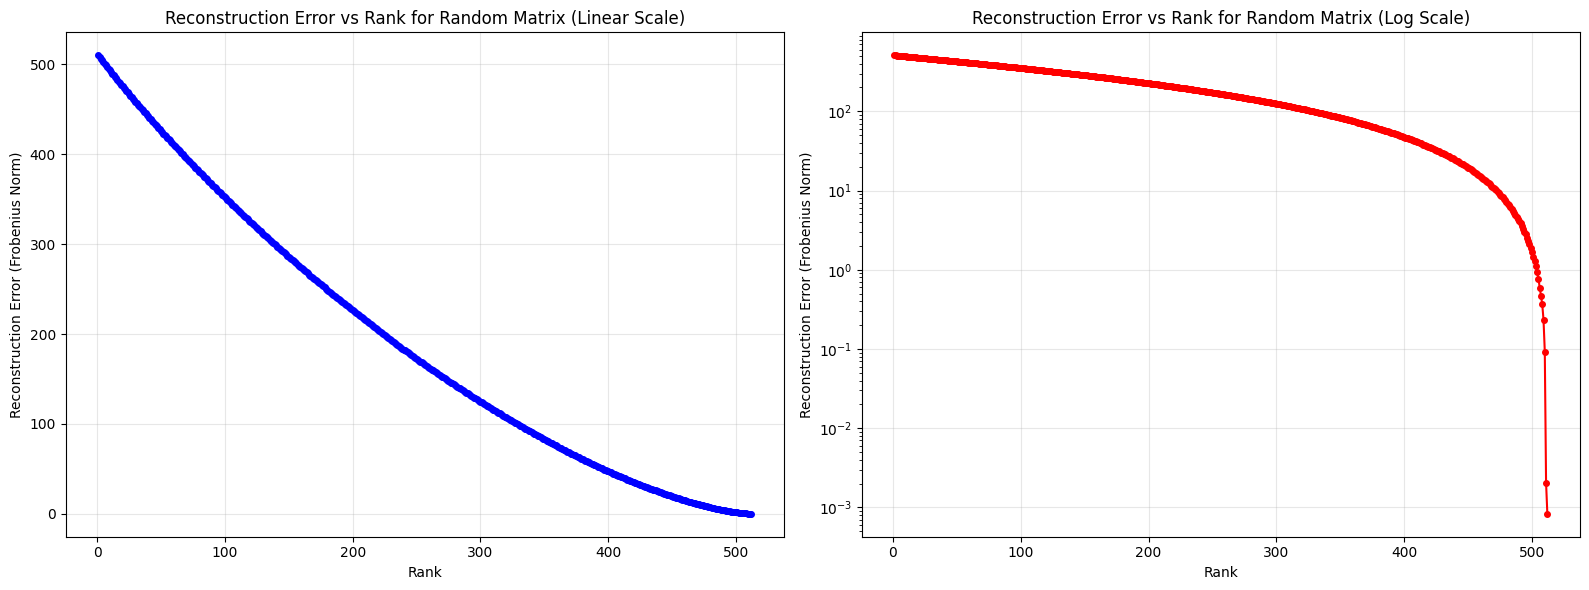

In [26]:
import torch
# A random matrix
A = torch.randn(512, 512)
max_rank = min(A.shape)
random_ranks, random_errors = plot_error_vs_rank(A, max_rank=max_rank, task='Random Matrix')

Analyzing MNIST Activations with shape torch.Size([512, 512])
  Rank 1/512: Error = 4.91981e+02
  Rank 2/512: Error = 4.68855e+02
  Rank 3/512: Error = 4.49261e+02
  Rank 4/512: Error = 4.31076e+02
  Rank 5/512: Error = 4.14230e+02
  Rank 6/512: Error = 3.97476e+02
  Rank 7/512: Error = 3.85596e+02
  Rank 8/512: Error = 3.74293e+02
  Rank 9/512: Error = 3.64138e+02
  Rank 10/512: Error = 3.55086e+02
  Rank 11/512: Error = 3.46271e+02
  Rank 12/512: Error = 3.38558e+02
  Rank 13/512: Error = 3.31446e+02
  Rank 14/512: Error = 3.24572e+02
  Rank 15/512: Error = 3.17892e+02
  Rank 16/512: Error = 3.11789e+02
  Rank 17/512: Error = 3.05782e+02
  Rank 18/512: Error = 3.00237e+02
  Rank 19/512: Error = 2.94950e+02
  Rank 20/512: Error = 2.89708e+02
  Rank 21/512: Error = 2.84805e+02
  Rank 22/512: Error = 2.80227e+02
  Rank 23/512: Error = 2.75703e+02
  Rank 24/512: Error = 2.71488e+02
  Rank 25/512: Error = 2.67560e+02
  Rank 26/512: Error = 2.63727e+02
  Rank 27/512: Error = 2.59906e+02
  

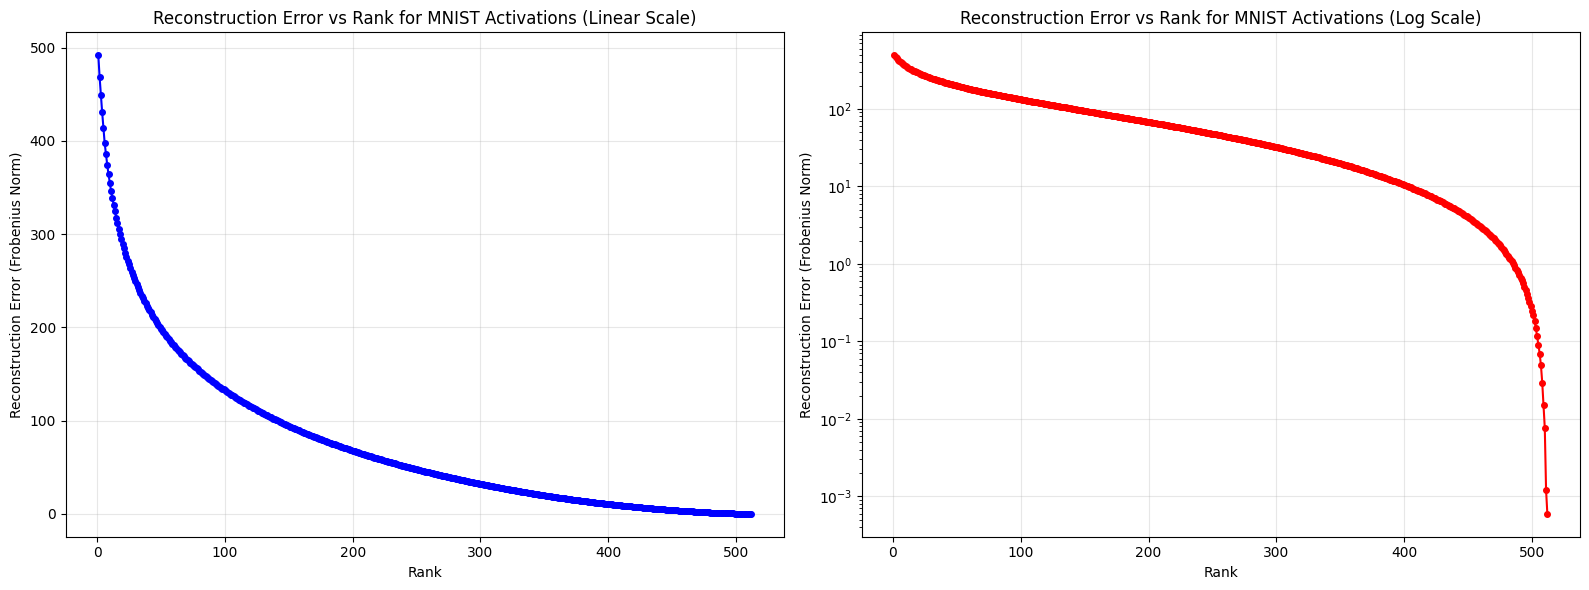

In [27]:
import torch
# Intermediate activation of a Fully connected network (trained on MNIST)
A = torch.load("data/mnist_act.pt")['act.1']
max_rank = min(A.shape)
mnist_act_ranks, mnist_act_errors = plot_error_vs_rank(A, max_rank, task='MNIST Activations')

Analyzing Neural Network Weights with shape torch.Size([128, 512])
  Rank 1/128: Error = 1.17076e+01
  Rank 2/128: Error = 1.10383e+01
  Rank 3/128: Error = 1.04338e+01
  Rank 4/128: Error = 9.89398e+00
  Rank 5/128: Error = 9.37535e+00
  Rank 6/128: Error = 8.94267e+00
  Rank 7/128: Error = 8.55202e+00
  Rank 8/128: Error = 8.20511e+00
  Rank 9/128: Error = 7.90542e+00
  Rank 10/128: Error = 7.70174e+00
  Rank 11/128: Error = 7.56201e+00
  Rank 12/128: Error = 7.42778e+00
  Rank 13/128: Error = 7.31607e+00
  Rank 14/128: Error = 7.21311e+00
  Rank 15/128: Error = 7.11262e+00
  Rank 16/128: Error = 7.01745e+00
  Rank 17/128: Error = 6.92488e+00
  Rank 18/128: Error = 6.83523e+00
  Rank 19/128: Error = 6.74606e+00
  Rank 20/128: Error = 6.66644e+00
  Rank 21/128: Error = 6.58861e+00
  Rank 22/128: Error = 6.51198e+00
  Rank 23/128: Error = 6.43908e+00
  Rank 24/128: Error = 6.36869e+00
  Rank 25/128: Error = 6.29912e+00
  Rank 26/128: Error = 6.23010e+00
  Rank 27/128: Error = 6.16337e+

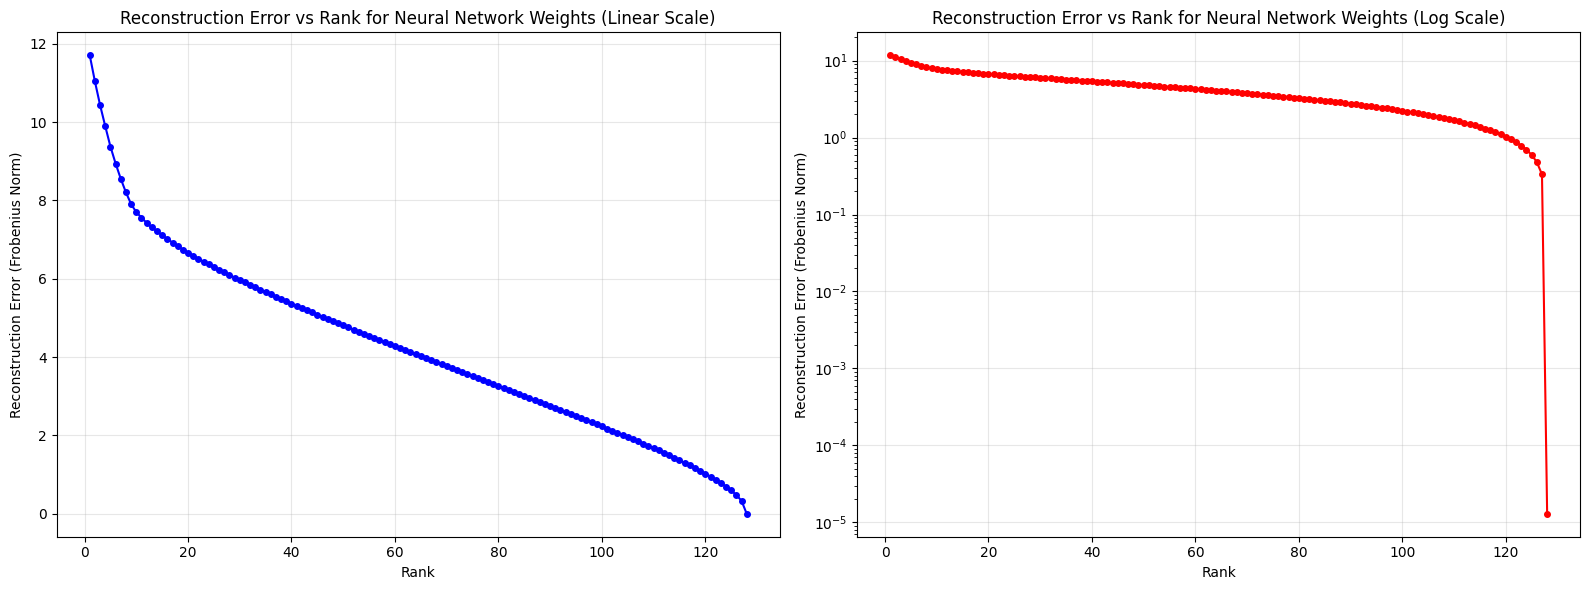

In [28]:
import torch
# Weight matrix of a fully connected neural network (trained on MNIST)
A = torch.load("data/mnist_fc.pt")['fc2.weight']
max_rank = min(A.shape)
nn_weights_ranks, nn_weights_errors = plot_error_vs_rank(A, max_rank, task='Neural Network Weights')

# 2. Rank v.s. Speed up

In this following cell(s), please plot the number of ranks preserved for A matrix (in the x-axis)
and the speed up of matrix-matrix multiply (in the y-axis, measured by both FLOPs and clock time)

You can assume both matrix A and B are using the same number of rank when approximating.

In [45]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [46]:
def measure_avg_matmul_time(A, B, num_trials):
  times = []
  for _ in range(num_trials):
        start = time.time()
        _ = A @ B
        end = time.time()
        times.append(end - start)
  return sum(times) / num_trials

In [53]:
import time
from src.matmul import svd

def compare_matmul_svd_speedup_and_flops(A, B, rank_values, num_trials=5):
    """Measure and plot speedup for just the matrix multiplication phase using SVD approximation with different ranks"""
    A.to(device)
    B.to(device)

    # Calculate baseline (naive matrix multiplication)
    avg_baseline_time = measure_avg_matmul_time(A, B, num_trials)
    print(f"Baseline matrix multiplication average time: {avg_baseline_time:.6f} seconds")

    A_rows, A_cols = A.shape
    B_rows, B_cols = B.shape
    baseline_flops = 2 * A_rows * A_cols * B_cols

    time_speedups = []
    flop_speedups = []

    for rank in rank_values:
        A_approx, B_approx = svd(
            A,
            B,
            rank_A=rank,
            rank_B=rank,
            return_approx_matrices=True
          )

        avg_approx_time = measure_avg_matmul_time(A_approx, B_approx, num_trials)

        time_speedup = avg_baseline_time / avg_approx_time
        time_speedups.append(time_speedup)

        # approx_flops = (
        #     rank * (
        #         A_rows * A_cols + B_rows * B_cols
        #     )
        # )

        approx_flops = (
            (
                2
                * (rank ** 2)
                * (
                    A_cols
                    + A_rows
                    + 1
                )
            )
            + (
                2
                * rank
                * A_rows
                * B_cols
            )
        )

        flop_speedup = baseline_flops / approx_flops
        flop_speedups.append(flop_speedup)

        print(f"Rank {rank}: Time speedup = {time_speedup:.2f}x, Theoretical FLOP speedup = {flop_speedup:.2f}x")

        torch.cuda.empty_cache()

    return time_speedups, flop_speedups

In [54]:
import torch
# Intermediate activation of a Fully connected network (trained on MNIST)
A = torch.load("data/mnist_act.pt")['act.1']

# Weight matrix of a fully connected neural network (trained on MNIST)
B = torch.load("data/mnist_fc.pt")['fc2.weight'].transpose(0, 1)

In [55]:
rank_values = range(
    1,
    min(A.shape[1], B.shape[0]) + 1
)
time_speedups, flop_speedups = compare_matmul_svd_speedup_and_flops(A, B, rank_values)

Baseline matrix multiplication average time: 0.000952 seconds
Rank 1: Time speedup = 1.04x, Theoretical FLOP speedup = 504.12x
Rank 2: Time speedup = 1.07x, Theoretical FLOP speedup = 248.24x
Rank 3: Time speedup = 1.14x, Theoretical FLOP speedup = 163.02x
Rank 4: Time speedup = 1.06x, Theoretical FLOP speedup = 120.46x
Rank 5: Time speedup = 1.06x, Theoretical FLOP speedup = 94.97x
Rank 6: Time speedup = 0.87x, Theoretical FLOP speedup = 78.01x
Rank 7: Time speedup = 1.05x, Theoretical FLOP speedup = 65.93x
Rank 8: Time speedup = 1.04x, Theoretical FLOP speedup = 56.88x
Rank 9: Time speedup = 1.13x, Theoretical FLOP speedup = 49.87x
Rank 10: Time speedup = 0.97x, Theoretical FLOP speedup = 44.28x
Rank 11: Time speedup = 1.08x, Theoretical FLOP speedup = 39.71x
Rank 12: Time speedup = 1.06x, Theoretical FLOP speedup = 35.92x
Rank 13: Time speedup = 1.04x, Theoretical FLOP speedup = 32.73x
Rank 14: Time speedup = 1.04x, Theoretical FLOP speedup = 30.00x
Rank 15: Time speedup = 1.05x, Th

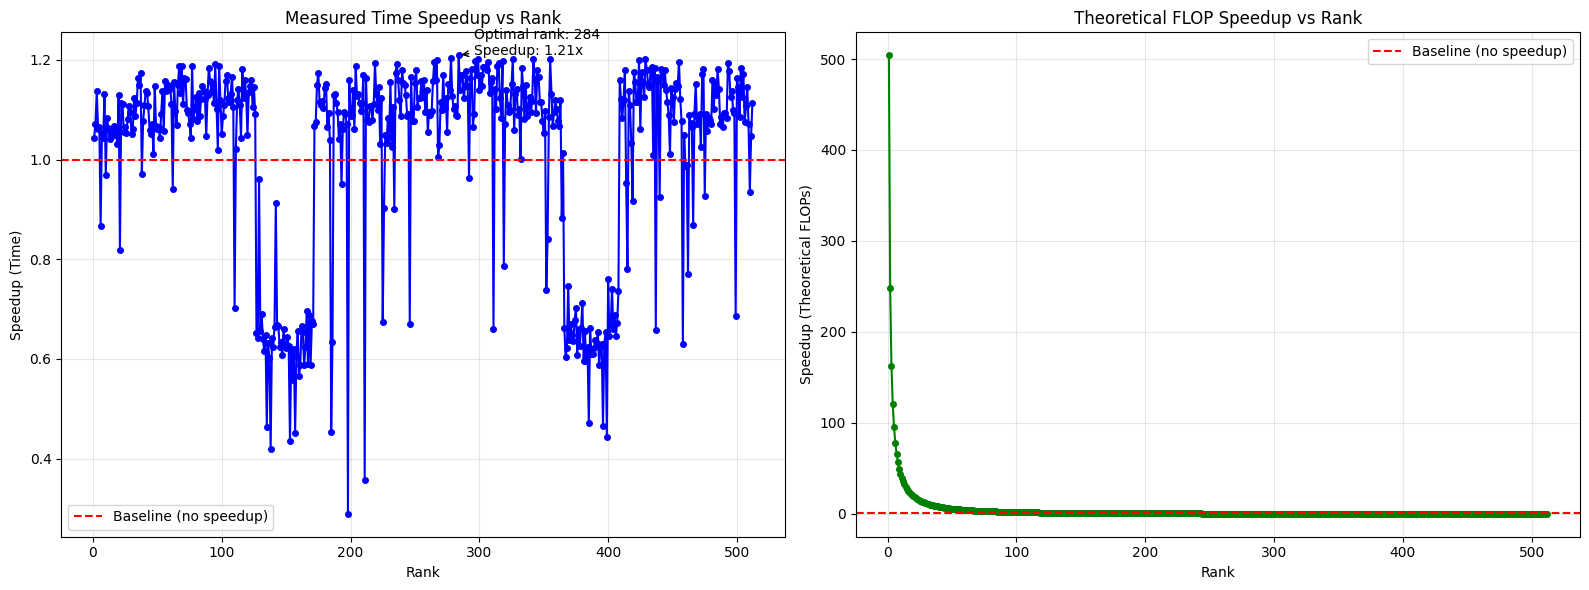

In [56]:
# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Time speedup plot
ax1.plot(rank_values, time_speedups, 'bo-', markersize=4)
ax1.axhline(y=1.0, color='r', linestyle='--', label='Baseline (no speedup)')
ax1.set_xlabel('Rank')
ax1.set_ylabel('Speedup (Time)')
ax1.set_title('Measured Time Speedup vs Rank')
ax1.grid(True, alpha=0.3)
ax1.legend()

# FLOP speedup plot
ax2.plot(rank_values, flop_speedups, 'go-', markersize=4)
ax2.axhline(y=1.0, color='r', linestyle='--', label='Baseline (no speedup)')
ax2.set_xlabel('Rank')
ax2.set_ylabel('Speedup (Theoretical FLOPs)')
ax2.set_title('Theoretical FLOP Speedup vs Rank')
ax2.grid(True, alpha=0.3)
ax2.legend()

# Find optimal rank (best speedup)
max_time_speedup = max(time_speedups)
optimal_time_rank = rank_values[time_speedups.index(max_time_speedup)]

# Annotate optimal rank
ax1.annotate(f'Optimal rank: {optimal_time_rank}\nSpeedup: {max_time_speedup:.2f}x',
             xy=(optimal_time_rank, max_time_speedup),
             xytext=(optimal_time_rank + max_rank//10, max_time_speedup),
             arrowprops=dict(arrowstyle='->'))

plt.tight_layout()
plt.savefig('svd_speedup_mnist_act_weight.png')
plt.show()

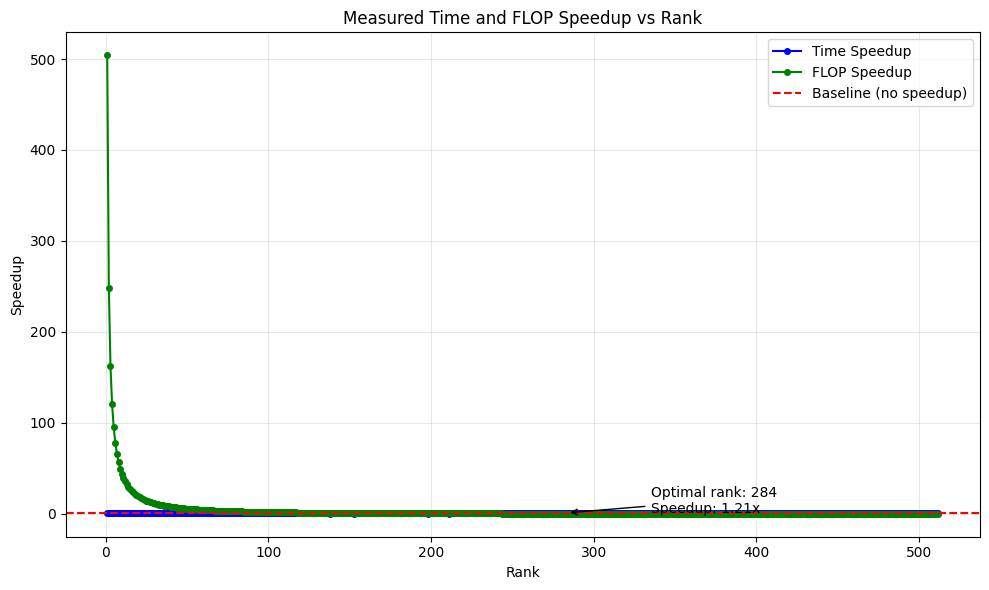

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot time speedup
plt.plot(rank_values, time_speedups, 'bo-', label='Time Speedup', markersize=4)

# Plot FLOP speedup
plt.plot(rank_values, flop_speedups, 'go-', label='FLOP Speedup', markersize=4)

# Baseline line
plt.axhline(y=1.0, color='r', linestyle='--', label='Baseline (no speedup)')

# Annotate optimal rank for time speedup
max_time_speedup = max(time_speedups)
optimal_time_rank = rank_values[time_speedups.index(max_time_speedup)]
plt.annotate(f'Optimal rank: {optimal_time_rank}\nSpeedup: {max_time_speedup:.2f}x',
             xy=(optimal_time_rank, max_time_speedup),
             xytext=(optimal_time_rank + max(rank_values)//10, max_time_speedup),
             arrowprops=dict(arrowstyle='->'))

plt.xlabel('Rank')
plt.ylabel('Speedup')
plt.title('Measured Time and FLOP Speedup vs Rank')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('svd_speedup_mnist_act_weight_combined.png')
plt.show()

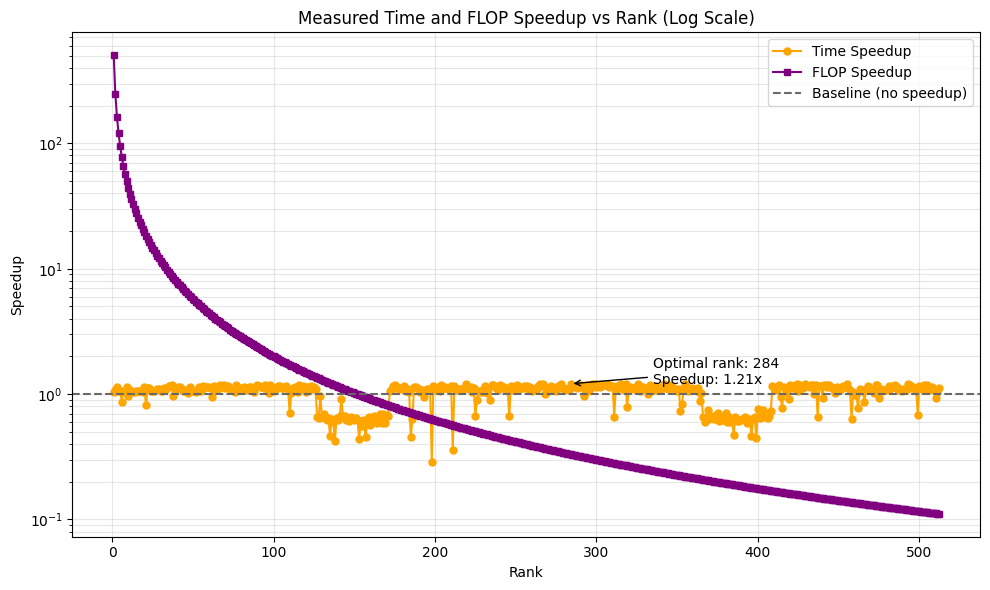

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot time speedup (orange)
plt.plot(rank_values, time_speedups, color='orange', marker='o', label='Time Speedup', markersize=5)

# Plot FLOP speedup (purple)
plt.plot(rank_values, flop_speedups, color='purple', marker='s', label='FLOP Speedup', markersize=5)

# Baseline line (dashed dark gray)
plt.axhline(y=1.0, color='dimgray', linestyle='--', label='Baseline (no speedup)')

# Annotate optimal rank for time speedup
max_time_speedup = max(time_speedups)
optimal_time_rank = rank_values[time_speedups.index(max_time_speedup)]
plt.annotate(f'Optimal rank: {optimal_time_rank}\nSpeedup: {max_time_speedup:.2f}x',
             xy=(optimal_time_rank, max_time_speedup),
             xytext=(optimal_time_rank + max(rank_values)//10, max_time_speedup),
             arrowprops=dict(arrowstyle='->', color='black'))

plt.xlabel('Rank')
plt.ylabel('Speedup')
plt.title('Measured Time and FLOP Speedup vs Rank (Log Scale)')
plt.yscale('log')
plt.grid(True, alpha=0.3, which='both')
plt.legend()
plt.tight_layout()
plt.savefig('svd_speedup_mnist_act_weight_combined_log.png')
plt.show()